In [7]:
# Basic libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import genpareto

# Optimization
from scipy.optimize import minimize
from scipy.stats import chi2
from scipy.stats import expon

## PART 1A: GPD operations for each station

In [ ]:
### FUNCTION DEFINITIONS ###

## DECLUSTERING ##
def runs_decluster(x, u, r):
    """
    x : pd.Series with a regular DatetimeIndex (NaNs allowed)
    u : threshold
    r : run length. Exceedances separated by >= r non-exceedances
        start a new cluster.
    Returns a DataFrame with one row per cluster.
    """
    x = x.copy()
    pos = np.flatnonzero((x > u).to_numpy())        # positions of exceedances
    if len(pos) == 0:
        return pd.DataFrame(columns=["start", "end", "size", "peak", "peak_time"])

    gaps = np.diff(pos)
    new_cluster = np.r_[True, gaps > r]             # gap-1 >= r  <=>  gap > r
    cluster_id = np.cumsum(new_cluster) - 1

    df = pd.DataFrame({
        "pos": pos,
        "time": x.index[pos],
        "value": x.to_numpy()[pos],
        "cluster": cluster_id,
    })

    out = df.groupby("cluster").apply(lambda g: pd.Series({
        "start": g["time"].iloc[0],
        "end": g["time"].iloc[-1],
        "size": len(g),                              # number of exceedances in cluster
        "peak": g["value"].max(),
        "peak_time": g.loc[g["value"].idxmax(), "time"],
    }))
    return out.reset_index(drop=True)

# EXTREMAL INDICES #
def extremal_index_runs(x, u, r):
    """Runs estimator: (# clusters) / (# exceedances)."""
    n_exc = (x > u).sum()
    n_cl = len(runs_decluster(x, u, r))
    return n_cl / n_exc

def extremal_index_intervals(x, u):
    """Ferro & Segers (2003) intervals estimator. No need to choose r."""
    pos = np.flatnonzero((x > u).to_numpy())
    N = len(pos)
    T = np.diff(pos)                                  # inter-exceedance times
    if T.max() <= 2:
        theta = 2 * T.sum() ** 2 / ((N - 1) * (T ** 2).sum())
    else:
        theta = 2 * (T - 1).sum() ** 2 / ((N - 1) * ((T - 1) * (T - 2)).sum())
    return min(1.0, theta)

# BASIC FIT #
def fit_gpd(values, u):
    excess = np.asarray(values) - u
    xi, loc, sigma = genpareto.fit(excess, floc=0)   # fix location at 0
    return xi, sigma

## BUILD EXCEEDANCE DATA ##
def build_exceedance_data(clusters, met, u, cols):
    d = met.loc[clusters["peak_time"], cols].copy()
    d["y"] = clusters["peak"].to_numpy() - u
    return d.dropna()

## LIKELIHOOD AND FIT ##

# NEGATIVE LOG LIKELIHOOD #
def gpd_nll(params, y, Z):
    """params = [beta_0..beta_p, xi]; Z includes the intercept column."""
    beta, xi = params[:-1], params[-1]
    sigma = np.exp(Z @ beta)
    if abs(xi) < 1e-6:                          # Gumbel limit (exponential excesses)
        return np.sum(np.log(sigma) + y / sigma)
    t = 1 + xi * y / sigma
    if np.any(t <= 0):                          # outside the support
        return 1e10
    return np.sum(np.log(sigma) + (1 + 1 / xi) * np.log(t))

# FITTING FUNCTION #
def fit_cov_gpd(data, covs, xi0=0.1):
    y = data["y"].to_numpy()
    mu, sd = data[covs].mean(), data[covs].std()
    Zc = ((data[covs] - mu) / sd).to_numpy() if covs else np.empty((len(data), 0))
    Z = np.column_stack([np.ones(len(data)), Zc])

    # start: intercept = log of the mean excess, other betas = 0
    x0 = np.r_[np.log(y.mean()), np.zeros(Z.shape[1] - 1), xi0]

    res = minimize(gpd_nll, x0, args=(y, Z), method="Nelder-Mead",
                   options={"maxiter": 20000, "xatol": 1e-6, "fatol": 1e-8})
    res = minimize(gpd_nll, res.x, args=(y, Z), method="BFGS")   # polish

    return {"params": res.x, "nll": res.fun, "k": len(res.x), "n": len(y),
            "names": ["intercept"] + covs + ["xi"],
            "mu": mu, "sd": sd, "Z": Z, "y": y, "covs": covs}
    
# SUMMARY #
def num_hessian(f, x, eps=1e-4):
    k = len(x)
    H = np.zeros((k, k))
    for i in range(k):
        for j in range(i, k):
            ei, ej = np.zeros(k), np.zeros(k)
            ei[i], ej[j] = eps, eps
            H[i, j] = H[j, i] = (f(x + ei + ej) - f(x + ei - ej)
                                 - f(x - ei + ej) + f(x - ei - ej)) / (4 * eps**2)
    return H

def summary(m):
    f = lambda p: gpd_nll(p, m["y"], m["Z"])
    cov = np.linalg.inv(num_hessian(f, m["params"]))
    se = np.sqrt(np.diag(cov))
    z = m["params"] / se
    from scipy.stats import norm
    out = pd.DataFrame({"coef": m["params"], "se": se, "z": z,
                        "p": 2 * (1 - norm.cdf(np.abs(z)))}, index=m["names"])
    out["exp(coef)"] = np.exp(out["coef"])        # meaningful for the betas only
    return out

# LIKELIHOOD TEST #
def lr_test(m_small, m_big):
    D = 2 * (m_small["nll"] - m_big["nll"])
    df = m_big["k"] - m_small["k"]
    return D, df, 1 - chi2.cdf(D, df)

# DIAGNOSTICS #
def residuals(m):
    beta, xi = m["params"][:-1], m["params"][-1]
    sigma = np.exp(m["Z"] @ beta)
    return np.log1p(xi * m["y"] / sigma) / xi

# SHOWCASE #
def excess_quantile(m, z_new, p):
    """Level exceeded by a fraction (1-p) of peaks under covariates z_new (dict)."""
    zs = np.array([(z_new[c] - m["mu"][c]) / m["sd"][c] for c in m["covs"]])
    sigma = np.exp(m["params"][0] + zs @ m["params"][1:-1])
    xi = m["params"][-1]
    return sigma / xi * ((1 - p) ** (-xi) - 1)

### Load and preprocess data

In [35]:
# Load
df = pd.read_csv("../data/datos_no_imputados.csv")

# Preprocess
df = df[["Fecha y hora", "Estacion", "O3", "PRS", "RAINF", "RH", "SR", "TOUT", "WSR", "WDR"]]
df["Fecha y hora"] = pd.to_datetime(df["Fecha y hora"])
df = df[(df["Fecha y hora"] >= "2023-01-01 00:00:00") & (df["Fecha y hora"] < "2026-01-01 00:00:00")]
df.set_index("Fecha y hora", inplace=True)
df.head()

,Estacion,O3,PRS,RAINF,RH,SR,TOUT,WSR,WDR
Fecha y hora,,,,,,,,,
2023-01-01 00:00:00,CE,9.0,718.4,0.0,45.0,0.000,17.65,4.9,236.0
2023-01-01 01:00:00,CE,9.0,710.7,0.0,47.0,0.001,17.12,3.4,336.0
2023-01-01 02:00:00,CE,11.0,710.4,0.0,46.0,0.001,16.69,3.4,3.0
2023-01-01 03:00:00,CE,11.0,710.1,0.0,48.0,0.001,15.99,2.6,315.0
2023-01-01 04:00:00,CE,9.0,710.2,0.0,55.0,0.001,14.74,3.9,270.0


In [37]:
STATIONS = list(df["Estacion"].unique())

stations = {
    "sensitivity": {},
    "data": {},
    "logit_data": {},
    "m0": {},
    "m1": {},
    "m2": {},
    "logit_models": {}
}

### Sensitivity Plots

In [9]:
rs = [6, 12, 24, 48, 72, 96]
u = 63
for station in STATIONS:
    x = df[df["Estacion"] == station]["O3"]
    res = []
    for r in rs:
        cl = runs_decluster(x, u, r)
        xi, sig = fit_gpd(cl["peak"], u)
        res.append({"r": r, "n_clusters": len(cl),
                    "theta": len(cl) / (x > u).sum(),
                    "xi": xi, "sigma": sig})
    stations["sensitivity"][station] = pd.DataFrame(res)

In [ ]:
# R vs NUM CLUSTERS

In [ ]:
# R vs THETA 

In [ ]:
# R vs XI

In [ ]:
# R vs SIGMA

### Compute data per station

In [14]:
for station in STATIONS:
    x = df[df["Estacion"] == station]["O3"]
    met = df[df["Estacion"] == station].drop(columns=["O3"])
    clusters = runs_decluster(x, u, r)

    # Feature Engineering
    met["wind_u"] = -met["WSR"] * np.sin(np.deg2rad(met["WDR"]))
    met["wind_v"] = -met["WSR"] * np.cos(np.deg2rad(met["WDR"]))
    met["hour_sin"] = np.sin(2 * np.pi * met.index.hour / 24)
    met["hour_cos"] = np.cos(2 * np.pi * met.index.hour / 24)
    met["month_sin"] = np.sin(2 * np.pi * met.index.month / 12)
    met["month_cos"] = np.cos(2 * np.pi * met.index.month / 12)

    cols = ["WSR", "TOUT", "RH", "PRS", "SR", "hour_sin", "hour_cos", "wind_u", "wind_v"]
    # cols = ["TOUT", "RH", "PRS", "SR", "hour_sin", "hour_cos", "wind_u", "wind_v"]
    # print(met[cols].corr())
    data = build_exceedance_data(clusters, met, u, cols)
    
    stations["data"][station] = data.copy()

Why declustering?

### Fit models

In [17]:
for station in STATIONS:
    m0 = fit_cov_gpd(stations["data"][station], [])                                               # stationary
    m1 = fit_cov_gpd(stations["data"][station], ["WSR", "TOUT", "RH"])                            # meteorological
    m2 = fit_cov_gpd(stations["data"][station], ["WSR", "TOUT", "RH", "hour_sin", "hour_cos"])    # + hour
    
    stations["m0"][station] = m0
    stations["m1"][station] = m1
    stations["m2"][station] = m2

#### Summaries

In [18]:
print(summary(stations["m0"]["SUR"]).round(3))

[[ 0.05158838 -0.02980882]
 [-0.02980882  0.02463147]]
            coef     se       z     p  exp(coef)
intercept  3.657  0.227  16.099  0.00     38.730
xi        -0.238  0.157  -1.515  0.13      0.788


In [19]:
print(summary(stations["m0"]["SUR"]).round(3))

[[ 0.05158838 -0.02980882]
 [-0.02980882  0.02463147]]
            coef     se       z     p  exp(coef)
intercept  3.657  0.227  16.099  0.00     38.730
xi        -0.238  0.157  -1.515  0.13      0.788


In [20]:
print(summary(stations["m0"]["SUR"]).round(3))

[[ 0.05158838 -0.02980882]
 [-0.02980882  0.02463147]]
            coef     se       z     p  exp(coef)
intercept  3.657  0.227  16.099  0.00     38.730
xi        -0.238  0.157  -1.515  0.13      0.788


#### Evaluation

In [21]:
for station in STATIONS:
    m0 = stations["m0"][station]
    m1 = stations["m1"][station]
    m2 = stations["m2"][station]

    print(f"\n---ESTACIÓN : {station}---")
    for name, (a, b) in {"met vs stationary": (m0, m1),
                        "+hour vs met": (m1, m2)}.items():
        D, df, p = lr_test(a, b)
        print(f"{name}: D={D:.2f}, df={df}, p={p:.4f}")

    for name, m in {"stationary": m0, "met": m1, "met+hour": m2}.items():
        print(name, "AIC =", round(2 * m["nll"] + 2 * m["k"], 1))


---ESTACIÓN : CE---
met vs stationary: D=22.86, df=3, p=0.0000
+hour vs met: D=-0.41, df=2, p=1.0000
stationary AIC = 351.5
met AIC = 334.7
met+hour AIC = 339.1

---ESTACIÓN : NE---
met vs stationary: D=17.03, df=3, p=0.0007
+hour vs met: D=-3.39, df=2, p=1.0000
stationary AIC = 215.4
met AIC = 204.4
met+hour AIC = 211.8

---ESTACIÓN : NE2---
met vs stationary: D=6.79, df=3, p=0.0788
+hour vs met: D=13.11, df=2, p=0.0014
stationary AIC = 268.5
met AIC = 267.7
met+hour AIC = 258.6

---ESTACIÓN : NE3---
met vs stationary: D=14.90, df=3, p=0.0019
+hour vs met: D=-0.68, df=2, p=1.0000
stationary AIC = 255.9
met AIC = 247.0
met+hour AIC = 251.7

---ESTACIÓN : NO---
met vs stationary: D=10.72, df=3, p=0.0133
+hour vs met: D=-1.80, df=2, p=1.0000
stationary AIC = 295.0
met AIC = 290.3
met+hour AIC = 296.1

---ESTACIÓN : NO2---
met vs stationary: D=11.42, df=3, p=0.0097
+hour vs met: D=2.45, df=2, p=0.2934
stationary AIC = 209.7
met AIC = 204.3
met+hour AIC = 205.8

---ESTACIÓN : NO3---
met v

#### Diagnostics

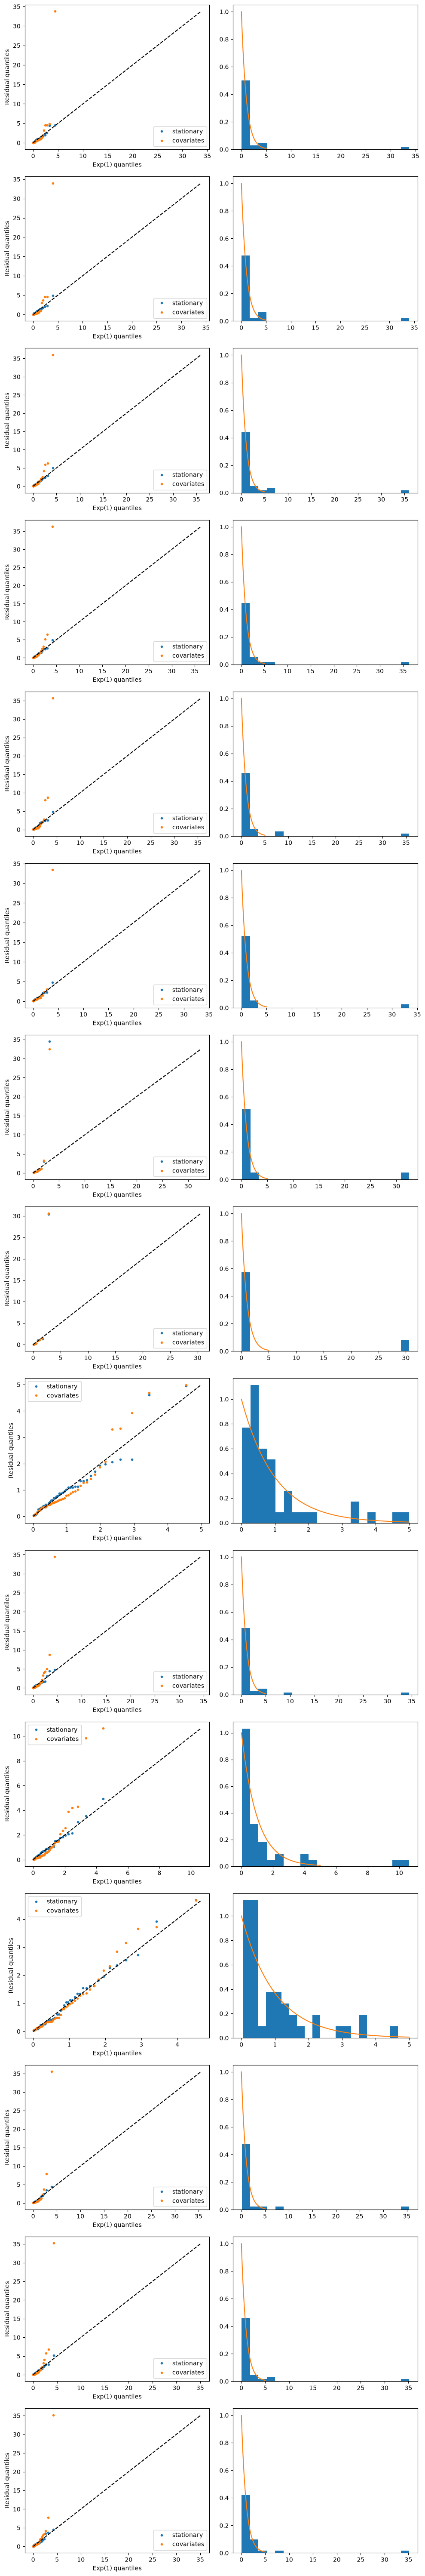

In [30]:
fig, ax = plt.subplots(15, 2, figsize=(10, 60))
for j, station in enumerate(STATIONS):
    m0 = stations["m0"][station]
    m1 = stations["m1"][station]
    m2 = stations["m2"][station]
    for m, lab in [(m0, "stationary"), (m2, "covariates")]:
        e = np.sort(residuals(m))
        q = expon.ppf((np.arange(1, len(e) + 1) - 0.5) / len(e))
        ax[j, 0].plot(q, e, "o", ms=3, label=lab)
    lim = [0, max(q.max(), e.max())]
    ax[j, 0].plot(lim, lim, "k--"); ax[j, 0].set_xlabel("Exp(1) quantiles")
    ax[j, 0].set_ylabel("Residual quantiles"); ax[j, 0].legend()
    ax[j, 1].hist(residuals(m2), bins=20, density=True)
    ax[j, 1].plot(np.linspace(0, 5), expon.pdf(np.linspace(0, 5)))
plt.tight_layout()

#### Showcase

In [31]:
m2 = stations["m2"]["SUR"]
calm = dict(WSR=0.5, TOUT=8, RH=80, hour_sin=0, hour_cos=1)
windy = dict(WSR=6, TOUT=30, RH=40, hour_sin=0, hour_cos=1)
for name, s in [("calm/cold", calm), ("windy/warm", windy)]:
    print(name, "-> 95th pct of excess:", u + excess_quantile(m2, s, 0.95))

calm/cold -> 95th pct of excess: 64.38569025961385
windy/warm -> 95th pct of excess: 72.98486490042959


## Part 1B

In [32]:
# More libraries
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

In [79]:
### FUNCTION DEFINITIONS ###

## BUILD DATA ##
def build_logit_data(x, met, u, horizon=1):
    """
    x   : hourly series
    met : DataFrame of hourly covariates, same index as x
    horizon : steps ahead to predict (1 = tomorrow)
    """
    d = pd.DataFrame(index=x.index)
    d["y"] = (x.shift(-horizon) > u).astype(float)
    d.loc[x.shift(-horizon).isna(), "y"] = np.nan

    # --- persistence-type features (the strongest predictors) ---
    d["x_t"] = x                                   # current level
    d["exc_t"] = (x > u).astype(float)             # exceeded now?
    d["x_lag1"] = x.shift(1)
    d["x_lag24"] = x.shift(24)
    d["max36"] = x.rolling(36).max()               # recent peak
    d["n_exc7"] = (x > u).astype(float).rolling(7).sum()   # recent episode activity

    # --- meteorology ---
    for c in ["WSR", "TOUT", "RH", "PRS", "SR"]:
        d[c] = met[c]
    d["wind_u"], d["wind_v"] = met["wind_u"], met["wind_v"]
    d["month_sin"] = np.sin(2 * np.pi * x.index.month / 12)
    d["month_cos"] = np.cos(2 * np.pi * x.index.month / 12)
    return d.dropna()


## LOGIT OPS ##
def fit_logit(train, feats):
    mu, sd = train[feats].mean(), train[feats].std()
    Z = sm.add_constant((train[feats] - mu) / sd)
    res = sm.Logit(train["y"], Z).fit(disp=0)
    return res, mu, sd

def predict_logit(res, mu, sd, df, feats):
    Z = sm.add_constant((df[feats] - mu) / sd, has_constant="add")
    return res.predict(Z)


## COMBINATION ##

# BUILD DATA #
def build_all_exceedance_data(x, met, u, cols):
    idx = x.index[x > u]
    dd = met.loc[idx, cols].copy()
    dd["y"] = x.loc[idx].to_numpy() - u
    return dd.dropna()

# COMPUTE PROBABILITIES #
def prob_exceed(c, zeta, sigma, xi, u):
    """P(X > c) = zeta * (1 + xi (c-u)/sigma)^(-1/xi) for c > u."""
    if c <= u:
        return np.ones_like(zeta)
    t = np.maximum(1 + xi * (c - u) / sigma, 0)     # t=0 -> prob 0 (bounded tail)
    surv = np.exp(-(c - u) / sigma) if abs(xi) < 1e-6 else t ** (-1 / xi)
    print("Zeta:", zeta, "Surv:", surv)
    return zeta * surv

def two_part_prob(c, df_row_or_frame, logit_model, gpd_model, u):
    res, mu, sd, feats = logit_model
    zeta = predict_logit(res, mu, sd, df_row_or_frame, feats).to_numpy()

    covs = gpd_model["covs"]
    Zs = ((df_row_or_frame[covs] - gpd_model["mu"]) / gpd_model["sd"]).to_numpy()
    sigma = np.exp(gpd_model["params"][0] + Zs @ gpd_model["params"][1:-1])
    xi = gpd_model["params"][-1]
    return prob_exceed(c, zeta, sigma, xi, u)

### Build Logit Data

In [38]:
u = 63.0
for station in STATIONS:
    x = df[df["Estacion"] == station]["O3"]
    met = df[df["Estacion"] == station].drop(columns=["O3"])

    # Feature Engineering
    met["wind_u"] = -met["WSR"] * np.sin(np.deg2rad(met["WDR"]))
    met["wind_v"] = -met["WSR"] * np.cos(np.deg2rad(met["WDR"]))
    met["hour_sin"] = np.sin(2 * np.pi * met.index.hour / 24)
    met["hour_cos"] = np.cos(2 * np.pi * met.index.hour / 24)
    met["month_sin"] = np.sin(2 * np.pi * met.index.month / 12)
    met["month_cos"] = np.cos(2 * np.pi * met.index.month / 12)

    d = build_logit_data(x, met, u)
    stations["logit_data"][station] = d.copy()
    print("Station:", station,"- Event rate:", d["y"].mean(), "| n =", len(d))

Station: CE - Event rate: 0.08196580462239024 | n = 11639
Station: NE - Event rate: 0.045561139028475715 | n = 5970
Station: NE2 - Event rate: 0.024372977346278316 | n = 9888
Station: NE3 - Event rate: 0.025031955688112485 | n = 9388
Station: NO - Event rate: 0.07613946649863475 | n = 9522
Station: NO2 - Event rate: 0.1033983286908078 | n = 8975
Station: NO3 - Event rate: 0.06584362139917696 | n = 4374
Station: NTE - Event rate: 0.033690658499234305 | n = 1959
Station: NTE2 - Event rate: 0.045282105093227866 | n = 12389
Station: SE - Event rate: 0.056924241150256454 | n = 11893
Station: SE2 - Event rate: 0.030539772727272728 | n = 9856
Station: SE3 - Event rate: 0.0291289592760181 | n = 14144
Station: SO - Event rate: 0.043186019156444294 | n = 5951
Station: SO2 - Event rate: 0.07742754389676328 | n = 14181
Station: SUR - Event rate: 0.06621756105029472 | n = 13063


### Split data

In [41]:
split = "2025-01-01 00:00:00"

feat_sets = {
"persistence-type": ["x_t", "exc_t", "max36", "n_exc7"],
"+ meteorology": ["x_t", "exc_t", "max36", "n_exc7",
                    "WSR", "TOUT", "RH", "wind_u", "wind_v"],
"+ season": ["x_t", "exc_t", "max36", "n_exc7",
                "WSR", "TOUT", "RH", "wind_u", "wind_v",
                "month_sin", "month_cos"],
}

for station in STATIONS:
    d = stations["logit_data"][station]
    train, test = d[d.index < split], d[d.index >= split]
    
    print(f"\n---ESTACIÓN : {station}---")
    # Baselines
    print("Persistence AUC (x_t as score):", round(roc_auc_score(test["y"], test["x_t"]), 3))

    models = {}
    for name, feats in feat_sets.items():
        res, mu, sd = fit_logit(train, feats)
        p = predict_logit(res, mu, sd, test, feats)
        models[name] = (res, mu, sd, feats)
        print(f"{name:18s} AUC={roc_auc_score(test['y'], p):.3f}  "
            f"Brier={brier_score_loss(test['y'], p):.4f}")
        
    stations["logit_models"][station] = models


---ESTACIÓN : CE---
Persistence AUC (x_t as score): 0.968
persistence-type   AUC=0.973  Brier=0.0351
+ meteorology      AUC=0.974  Brier=0.0347
+ season           AUC=0.973  Brier=0.0356

---ESTACIÓN : NE---
Persistence AUC (x_t as score): 0.968
persistence-type   AUC=0.976  Brier=0.0303
+ meteorology      AUC=0.989  Brier=0.0243
+ season           AUC=0.989  Brier=0.0263

---ESTACIÓN : NE2---
Persistence AUC (x_t as score): 0.987
persistence-type   AUC=0.988  Brier=0.0093
+ meteorology      AUC=0.987  Brier=0.0093
+ season           AUC=0.984  Brier=0.0097

---ESTACIÓN : NE3---
Persistence AUC (x_t as score): 0.984
persistence-type   AUC=0.986  Brier=0.0212
+ meteorology      AUC=0.981  Brier=0.0221
+ season           AUC=0.981  Brier=0.0227

---ESTACIÓN : NO---
Persistence AUC (x_t as score): 0.974
persistence-type   AUC=0.980  Brier=0.0327
+ meteorology      AUC=0.984  Brier=0.0325
+ season           AUC=0.984  Brier=0.0328

---ESTACIÓN : NO2---
Persistence AUC (x_t as score): 0.97

/Users/ricardosalgadob/Desktop/Multivariados/MultiReto/.venv/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/ricardosalgadob/Desktop/Multivariados/MultiReto/.venv/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/Users/ricardosalgadob/Desktop/Multivariados/MultiReto/.venv/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/Users/ricardosalgadob/Desktop/Multivariados/MultiReto/.venv/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/Users/ricardosalgad

### Interpretation and Significance

In [42]:
res = stations["logit_models"]["SUR"]["+ meteorology"][0]
print(res.summary())

out = pd.DataFrame({"coef": res.params, "odds_ratio": np.exp(res.params),
                    "p": res.pvalues})
print(out.round(3))

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 6399
Model:                          Logit   Df Residuals:                     6389
Method:                           MLE   Df Model:                            9
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.7003
Time:                        23:48:59   Log-Likelihood:                -285.96
converged:                       True   LL-Null:                       -954.30
Covariance Type:            nonrobust   LLR p-value:                3.713e-282
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -6.9835      0.369    -18.915      0.000      -7.707      -6.260
x_t            2.1459      0.195     11.022      0.000       1.764       2.527
exc_t          0.0661      0.072      0.919      0.3

In [ ]:
# LR Tests and AIC

### Calibration

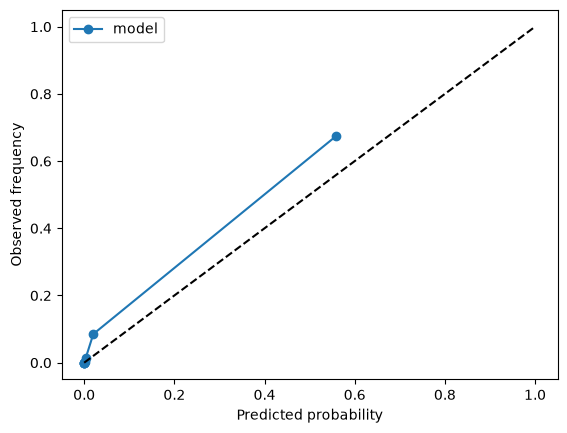

In [ ]:
res, mu, sd, feats = stations["logit_models"]["SUR"]["+ season"]
p = predict_logit(res, mu, sd, test, feats)
frac_pos, mean_pred = calibration_curve(test["y"], p, n_bins=8, strategy="quantile")

plt.plot(mean_pred, frac_pos, "o-", label="model")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency"); plt.legend()
plt.show();

### Combine

In [46]:
stations["gdata"] = {}
stations["mg"] = {}

In [48]:
gpd_cols = ["WSR", "TOUT", "RH"]
u = 63.0
for station in STATIONS:
    x = df[df["Estacion"] == station]["O3"]
    met = df[df["Estacion"] == station].drop(columns=["O3"])

    # Feature Engineering
    met["wind_u"] = -met["WSR"] * np.sin(np.deg2rad(met["WDR"]))
    met["wind_v"] = -met["WSR"] * np.cos(np.deg2rad(met["WDR"]))
    met["hour_sin"] = np.sin(2 * np.pi * met.index.hour / 24)
    met["hour_cos"] = np.cos(2 * np.pi * met.index.hour / 24)
    met["month_sin"] = np.sin(2 * np.pi * met.index.month / 12)
    met["month_cos"] = np.cos(2 * np.pi * met.index.month / 12)
    
    gdata = build_all_exceedance_data(x, met, u, gpd_cols)
    mg = fit_cov_gpd(gdata, gpd_cols)
    stations["gdata"][station] = gdata
    stations["mg"][station] = mg

In [66]:
c = 90.0
for station in STATIONS:
    x = df[df["Estacion"] == station]["O3"]
    p_c = two_part_prob(c, test, stations["logit_models"][station]["+ meteorology"], stations["mg"][station], u)
    try:
        print("Station:", station, "\tMean predicted P(X>c):", p_c.mean(), "\t| observed:", (x.shift(-1).loc[test.index] > c).mean())
    except:
        print("Station:", station, "\tMean predicted P(X>c):", p_c.mean())

Station: CE 	Mean predicted P(X>c): 0.01765978073552306
Station: NE 	Mean predicted P(X>c): 0.007905641656796442
Station: NE2 	Mean predicted P(X>c): 0.006419034494814716
Station: NE3 	Mean predicted P(X>c): 0.003872921288777756 	| observed: 0.0031512605042016808
Station: NO 	Mean predicted P(X>c): 0.013760633536943626 	| observed: 0.01755702280912365
Station: NO2 	Mean predicted P(X>c): 0.021122405013276738
Station: NO3 	Mean predicted P(X>c): 0.021793111138185484 	| observed: 0.0055522208883553425
Station: NTE 	Mean predicted P(X>c): 0.0033651717372979706
Station: NTE2 	Mean predicted P(X>c): 0.008366005856489115
Station: SE 	Mean predicted P(X>c): 0.014788620470907487
Station: SE2 	Mean predicted P(X>c): 0.005683891629794972 	| observed: 0.004201680672268907
Station: SE3 	Mean predicted P(X>c): 0.012704356309004843
Station: SO 	Mean predicted P(X>c): 0.012215976055275263
Station: SO2 	Mean predicted P(X>c): 0.018698925801474673
Station: SUR 	Mean predicted P(X>c): 0.0148337053803533

In [88]:
p_c = two_part_prob(c, test.loc["2025-05-24 13:00:00":"2025-05-24 15:00:00"], stations["logit_models"]["SUR"]["+ meteorology"], stations["mg"]["SUR"], u)
print(p_c)

Zeta: [0.9390592  0.99792324 0.99971496] Surv: [0.16156727 0.20499966 0.28633312]
[0.15172123 0.20457392 0.2862515 ]


In [87]:
test.loc["2025-05-24 13:00:00":"2025-05-24 15:00:00"]

,y,x_t,exc_t,x_lag1,x_lag24,max36,n_exc7,WSR,TOUT,RH,PRS,SR,wind_u,wind_v,month_sin,month_cos
Fecha y hora,,,,,,,,,,,,,,,,
2025-05-24 13:00:00,1.0,80.0,1.0,55.0,53.0,80.0,1.0,7.1,31.49,53.0,710.6,0.751,0.123912,-7.098919,0.5,-0.866025
2025-05-24 14:00:00,1.0,104.0,1.0,80.0,50.0,104.0,2.0,7.2,32.72,49.0,710.1,0.720,0.877459,-7.146332,0.5,-0.866025
2025-05-24 15:00:00,1.0,119.0,1.0,104.0,49.0,119.0,3.0,6.9,34.46,43.0,709.6,0.651,5.437274,-4.248064,0.5,-0.866025
